# Introduction

This document outlines the notes and learnings from Chapter 2 of Data Science for Scratch, which is a python crash course. These notes are designed to support someone moving from R to python for data science work. 

As a reminder, some key shortcuts for work for jupyter
https://towardsdatascience.com/jypyter-notebook-shortcuts-bf0101a98330
or
https://datalya.com/blog/python-data-science/jupyter-notebook-command-mode-keyboard-shortcuts


On mac (no need for escape to enter command mode),
* `^ enter` runs/formats the current cell / `esc` leaves it
* `alt enter` runs cell and creates below
* `shift enter` runs cell and seleccts below
* `command shift enter` creates cell above you, 
* `command enter` creates cell below you -- use this a lot!
* `enter` to start editing a cell
* `up/down` arrows to scroll through cells
* `D`, `D` (double press) deletes selected cell
* `a` to create a cell above you, `b` to create a cell below you
* `c` copies cells, `x` cuts them, `v` pastes them, `shift + v` pastes above
* `y` makes cell code, `m` makes it markdown,  `r` makes it raw code  


# Formatting

As in R, spaces don't matter

In [1]:
print(1+2)
print(1 +         4)


3
5


The shell will return a value when you call and expression, but it is not actually printing.=

In [2]:
1+3

4

You can suppress this by using a `;` at the end

In [3]:
1+3;

Python uses spaces to create code blocks rather than curly braces

In [4]:
for i in [1, 2, 3, 4]:
    print(i)

1
2
3
4


... so be careful with spaces

In [5]:
for i in [1, 2, 3, 4]:
    print(i)
print("this won't loop")

1
2
3
4
this won't loop


You can use nested spaces to make code blocks. Note that this code uses `str()` to cast `i` and `j` as text; you concatatenate text with a `+`: 

In [6]:
for i in [1, 2, 3, 4]:
    print("i = "+str(i))
    for j in [5, 6, 7, 8]:
        print(str(i) + " and " + str(j))
    print("done with i = " + str(i))

i = 1
1 and 5
1 and 6
1 and 7
1 and 8
done with i = 1
i = 2
2 and 5
2 and 6
2 and 7
2 and 8
done with i = 2
i = 3
3 and 5
3 and 6
3 and 7
3 and 8
done with i = 3
i = 4
4 and 5
4 and 6
4 and 7
4 and 8
done with i = 4


The list is created with `[ ]` and is akin to `c()` in R. Since we are playing with lists, note that they are much more flexible with vectors in R. You can have a list of lists (in R, this would be akin to creating a 'vector of vectors')

In [7]:
x = [[1,2], [3, 4], [5, 6]]

How long is that list? It has three elements, so 3

In [8]:
len(x)

3

Note that this works a bit differently than in R, which flattens the result to a single vector.


# Modules

Options for loading a module (the python version of a "package")

1. Import the package, and call for it by name

In [9]:
import re
re.compile("[0-9]+")

re.compile(r'[0-9]+', re.UNICODE)

2. Import the package with an alias


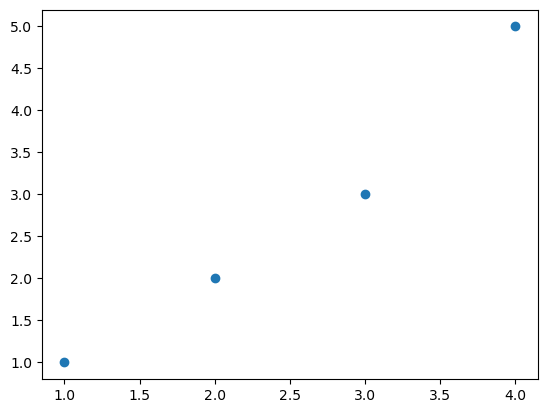

In [10]:
import matplotlib.pyplot as plt

plt.scatter(x=[1,2,3,4], y=[1,2,3,5])

3. Import a specific function from a package and it is used without qualification


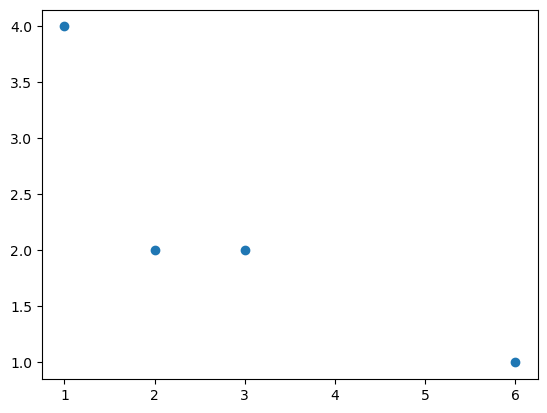

In [11]:
from matplotlib.pyplot import scatter

scatter(x=[1,2,6,3], y=[4,2,1,2])

4. You could also import ALL functions that way but don't do this as they will overwrite ANY variables in your namespace. BAD IDEA! 

`from matplotlib.pyplot import *` will cause anything with matching names to be overwritten.


# Functions

Create custom functions wth `def name():` and use triple quotes (`""""`) to create blocks of text that document the function. If you wish to return something, end the function with `return `.

In [12]:
def doubler(x):
    """
    This is how we document the function contents
    """
    return x*2

Try it out:

In [13]:
doubler(3)

6

Note that x there is a local variable, but you can declare a global variable with `global x`. 

In [14]:
x = "awful"

def myfunc(): 
    global x
    x = "fantastic"

print(x)

myfunc()

print(x)

awful
fantastic


There are a few neat function properties. 

### Functions can operate nested and evaluate from inside out

In [15]:
def add1k(x): 
    return x+ 1000

Try running that: 

In [16]:
add1k(30)

1030

Try nesting them

In [17]:
add1k(doubler(30))

1060

Easy! 

### I can also make a function that calls another function:

In [18]:
def double_me(x):
    return doubler(x)

Try that:

In [19]:
double_me(3)

6

Again, all very standard

### Funcations can be arguments and/or saved as vairables

This one is magic. You can create a function where the ARGUMENT is another function, and WHATEVER function you specify can be called. The trick is to save the function as a variable first (can't do that in R)

This flips the script. Usually your function is fixed and you specify the arguments. Now, your function can preset the argument values and pass them to WHATEVER function you give it.

This function takes a function as an argument, gives it the number 1 as an argument, and returns it:

In [20]:
def apply_your_function_to_1(fun):
    return fun(1)

In [21]:
#works directly
apply_your_function_to_1(doubler)

2

In [22]:
#or save as variable first
input = doubler
apply_your_function_to_1(input)

2

### Lambdas

declare a function on the fly with `lambda x: ....`

I don't see the use of this yet except as passing as an argument to a function that accepts a function as an input. However, i'm sure examples will come up.

In [23]:
apply_your_function_to_1(lambda x: x+4)

5

### Other function stuff

Like in R, you can give default argument values and only need to name your arguments in a function call if the order doesn't match the default

# Strings

Can use double or single quotes but must match

In [24]:
x = 'this is valid'
y = "so is this"
print(x + "; " + y)

this is valid; so is this


As in R, `\` is an escape character

In [25]:
print("\t hello")
print("\n hello")
print("\\ hello")
print("\' hello")

	 hello

 hello
\ hello
' hello


In [26]:
#this one is key becuase it doesn't kill the quotes
print("\" hello")

" hello


There are a few special kinds of strings

1. Raw strings ignore escape characters

In [27]:
r"\t"

'\\t'

2. f strings allow {} placeholders to dynamically populate from variables--no more concatenating!

In [28]:
x = "foo"
y = "bar"

f"{x} is my name and {y} is my game"

'foo is my name and bar is my game'

Before f-strings, there was also the format method. Use numbers (index at zero) and then add the format method to populate them:

In [29]:
"{0} is my name and {1} is my game".format("foo", "bar")

'foo is my name and bar is my game'

or 


In [30]:
"{0} is my name and {1} is my game".format(x, y)

'foo is my name and bar is my game'

Finally, block quotes are with triple quotes:


In [31]:
x = """This is a quote
with a lot of lines
don't you like it
ok done now"""

You need to print it for it to look right. The shell will spit it back out with the escape characters:

In [32]:
print(x)

This is a quote
with a lot of lines
don't you like it
ok done now


### Exceptions

When code has an error, it's called an exception

The program crashes if they are not *handled*. 

For this, use `try:` and `except ...:`. You use them in a pair and for `except` you have to list the exact error message you want to except for. Rather than crashing the program, it does an alternate command such as printing something. This lets the buggy code execute and skip the error!

In [33]:
try:
    print(0/0)
except ZeroDivisionError:
    print("can't do that!")

can't do that!


# Lists

List scan be inteegers, heterogenous, or even lists of lists. Functions such as `len()` and `sum()` may work or may not.


In [34]:
x = [1,2,3]
print("sum = "+str(sum(x)))
print("length = "+str(len(x)))

sum = 6
length = 3


In [35]:
x = [[1,2], [3, 4], [5, 6]]
len(x)

3

For the latter, we can try to sum but it won't like it:

In [36]:
try:
    sum(x)
except TypeError:
    print("you can't do that!")

you can't do that!


#### Slicing lists

Indexing and slicing lists is a big deal in python. 

First, lets create the numbers 1 through 9 as a vector. Instead of doing it manually, we can use `range()` which goes from the first number and stops SHORT of the second number. So, `range(1,10)` generates the values 1 through 9. We have to wrap that with `list()` to make a list out of it.

In [37]:
x = list(range(1,10))
print(x)

[1, 2, 3, 4, 5, 6, 7, 8, 9]


Cool! But I'm going to use letters here to avoid confusion: 

In [38]:
x = ['a', 'b', 'c', 'd', 'e', 'f', 'g', 'h', 'i', 'j']
print(x)

['a', 'b', 'c', 'd', 'e', 'f', 'g', 'h', 'i', 'j']


As in R, use `[]` to index but we index on zero now!

In [39]:
#recalls the fifth letter
x[4]

'e'

As in R, select a range of indices with a colon but here we include the first value (inclusive) **but not the second value** (exclusive):

In [40]:
# returns indices 0, 1, 2, 3
# aka first four
x[0:4]

['a', 'b', 'c', 'd']

Because we index on zero, that returns the first four values. Which is confusing becuase we aren't including index number 4 (the fifth index value). 


Lists can be overriden, so...

In [41]:
x[0] = "aaaaaa"
print(x)

['aaaaaa', 'b', 'c', 'd', 'e', 'f', 'g', 'h', 'i', 'j']


Unlike R, you can omit one value there to reference the beginning or end of the list:


In [42]:
#equivalent to positions 0 through 4:
# aka first five 
x[:5]

['aaaaaa', 'b', 'c', 'd', 'e']

In [43]:
# from the 6th letter to the end
x[5:]

['f', 'g', 'h', 'i', 'j']

Can go negative to count from the end. Notice that there is no -0

In [44]:
#last element
x[-1]

'j'

In [45]:
#next to last
x[-2]

'i'

There is no negative zero! -1 is the first value going from right to left...

In [46]:
try:
    x[-0]
except:
    print("there's no -0 index")

In [47]:
# from second to penultimate (without first and last)
# we index at zero, so we start at '1'
# the second value is EXCLUSIVE so we end JUST SHORT of -1 to get the SECOND TO LAST element
x[1:-1]

['b', 'c', 'd', 'e', 'f', 'g', 'h', 'i']

In [48]:
#Everything BEFORE (remember, exclusive) the last three!
x[:-3]

['aaaaaa', 'b', 'c', 'd', 'e', 'f', 'g']

In [49]:
#Everything IN (remember, inclusive) the last three
x[-3:]

['h', 'i', 'j']

#### WE CAN DO THIS FOR STRINGS OR ANY SEQUENTIAL TYPE!!

In [50]:
y = "this is a string"
print(y[0])
print(y[0:7])
print(y[4:-3])
#!!!!!

t
this is
 is a str


### There's a third argument, that's the stride

Use this for something like a sequence (counting 'by') or even as negative means to go in reverse

In [51]:
#from the 4th letter to the 8th letter (shy of pos 9), counting by two
x[3:8:2]

['d', 'f', 'h']

In [52]:
#string y in referse
y[ : : -1]

'gnirts a si siht'

### Test for membership

Works for lists

In [53]:
'z' in x

False

In [54]:
'e' in x

True

and strings

In [55]:
'e' in y

False

In [56]:
'i' in y

True

Magic! note that `in` is SLOW

## Extending and appending

addition for temporary concat


In [57]:
x = list(range(1,4))
print(x)

y = ['more', 'content']
print(y)

[1, 2, 3]
['more', 'content']


Try the concat:

In [58]:
x + y

[1, 2, 3, 'more', 'content']

If you want to mod them, use extend:


In [59]:
x.extend(y)

Now x has been extended:


In [60]:
print(x)

[1, 2, 3, 'more', 'content']


append adds a single value


In [61]:
x.append("wtf")

In [62]:
print(x)

[1, 2, 3, 'more', 'content', 'wtf']


## Unpacking lists

For whatever reason, this assigns each list element to `a`, `b`, and `c`. This only works if the number of names at left matches the length of the list at right. 

In [63]:
a, b, c = [1, 2, 3]

If you want to do this and throw away one, a common idiom is to use an underscore as the variable name


In [64]:
#we only care about grabbing c
_, _, c = [1, 2, 3]

This is useful when we output the results of a function as a list or tuple (usually a tuple). That will be akin to the blurb on the right. We want to grab and save those elements using this procedure.

# Tuples


Tuples are immutable versions of lists and are created with either `()` or nothing


In [65]:
x = 1, 2, 3, 4
print(x)
y = (4, 3, 2, 1)
print(y)

(1, 2, 3, 4)
(4, 3, 2, 1)


Use tuple as result of a function

In [66]:
def two_output(x):
    return (x+3), (x-3)
    

In [67]:
two_output(1)


(4, -2)

In [68]:
a, b = two_output(10)

In [69]:
print(a)
print(b)

13
7


in the above, we have saved the results of `two_output` as a tuple AND we have used a tuple in the `return` portion of the function. 



Similary, use tuple to assign two variables at once (multiple assignment):

In [70]:
x, y = 1, 2
print(x)
print(y)

1
2


that can be done with a list as well

You can also use a tuple to swap variable values


In [71]:
x, y = y, x

In [72]:
print(x)
print(y)

2
1


# Dictionaries


Dictionaries are bassicaly JSON in python and is one way to store data as key/value pairs

In [109]:
#empty one
dict ={}


In [110]:
#with data
dict = {
    "Tom": "cool", 
    "Ben": "cooler", 
    "Steve": 100
    }

In [111]:
print(dict)

{'Tom': 'cool', 'Ben': 'cooler', 'Steve': 100}


In [112]:
'Ben' in dict

True

You can referencde keys and values

In [113]:
'Ben' in dict.keys()

True

But default is to check keys so you can just omit that:

In [114]:
'Ben' in dict

True

Must check values directly:

In [115]:
'Ben' in dict.values()

False

In [116]:
print(dict["Ben"])
print(dict["Steve"])

cooler
100


Throws error if you look for a key that's not there

In [117]:
try:
    dict["Carl"]
except:
    print("carl is missing")

carl is missing


grab values out

In [118]:
value1 = dict["Ben"]
print(value1)

cooler


The real value here is that you can use the `.get()` method to pull values out and it has a default value if missing


In [119]:
dict.get("Ben")


'cooler'

In [120]:
#illustrate default default value of 'None'
print(dict.get("Benny"))

None


In [121]:
#illustrate provided default valuve
print(dict.get("Benny", 9))

9


Another nice feature is that you can create new values on assignment


In [122]:
dict["Bravo"] = "Monica"
print(dict["Bravo"])

Monica


In [123]:
# prove that it worked
print(dict)
len(dict)

{'Tom': 'cool', 'Ben': 'cooler', 'Steve': 100, 'Bravo': 'Monica'}


4

You can also have lists as values

In [124]:
dict["longerfield"] = ["hello", "world", "how", "are", "you"]
print(dict)


{'Tom': 'cool', 'Ben': 'cooler', 'Steve': 100, 'Bravo': 'Monica', 'longerfield': ['hello', 'world', 'how', 'are', 'you']}


## Query Dictionaries

You can use the `.keys()` and `.values()` methods or the `.items()` method to get all of them


In [125]:
dict.keys()

dict_keys(['Tom', 'Ben', 'Steve', 'Bravo', 'longerfield'])

In [126]:
dict.values()

dict_values(['cool', 'cooler', 100, 'Monica', ['hello', 'world', 'how', 'are', 'you']])

In [127]:
#returns tuples, one for each key/value pair
dict.items()

dict_items([('Tom', 'cool'), ('Ben', 'cooler'), ('Steve', 100), ('Bravo', 'Monica'), ('longerfield', ['hello', 'world', 'how', 'are', 'you'])])

Notice that that isn't a list of tuples, it's a `dict_items` object

In [137]:
out = dict.items()

In [138]:
type(out)

dict_items

Want to see what methods are available for a class? use `dir()`

In [130]:
dir(out)

['__and__',
 '__class__',
 '__contains__',
 '__delattr__',
 '__dir__',
 '__doc__',
 '__eq__',
 '__format__',
 '__ge__',
 '__getattribute__',
 '__getstate__',
 '__gt__',
 '__hash__',
 '__init__',
 '__init_subclass__',
 '__iter__',
 '__le__',
 '__len__',
 '__lt__',
 '__ne__',
 '__new__',
 '__or__',
 '__rand__',
 '__reduce__',
 '__reduce_ex__',
 '__repr__',
 '__reversed__',
 '__ror__',
 '__rsub__',
 '__rxor__',
 '__setattr__',
 '__sizeof__',
 '__str__',
 '__sub__',
 '__subclasshook__',
 '__xor__',
 'isdisjoint',
 'mapping']

Create a *list comprehension* to review that. It has the following format

`[expression for item in iterable if condition]` 

It iterates over a list and returns a transform of it. NICE!

In [131]:
#oops! ad an if not

[method for method in dir(out) if not method.startswith('__')]


['isdisjoint', 'mapping']

In [132]:
#you have a name of an object, you go through it, and apply the method to the object
# doesn't matter what you call it
[fart for fart in dir(out) if not fart.startswith('__')]


['isdisjoint', 'mapping']

Try the options? in this case, neither work. go back to dictionaries



In [133]:
#check if something is a key the bad way
"Tom" in dict.keys()


True

In [134]:
#simpler way, so more pythonic
"Tom" in dict

True

In [135]:
#can also query values--considered slow but only way to check
"cooler" in dict.values()

True

In [136]:
#note that it will NOT query the values by default
"cooler" in dict

False

## Default Dict